# Customer Segmentation Project 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np

In [2]:
dataset = pd.read_csv(r"customer_segmentation data.csv")
dataset.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
dataset.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [4]:
dataset.shape

(200, 5)

# labelencoding

In [5]:
from sklearn.preprocessing import LabelEncoder

In [6]:
end_data = dataset["Gender"]

In [7]:
ll = LabelEncoder()

In [8]:
dataset["en_gender"] = ll.fit_transform(end_data)

In [9]:
en_gender = dataset["en_gender"]

In [10]:
dataset = dataset.drop(columns=["Gender"])

In [11]:
# sns.pairplot(data=dataset)
# plt.show()

# KMeans Clustering 

In [12]:
# use elbow method to find the best cluster

In [13]:
from sklearn.preprocessing import StandardScaler

In [14]:
ss = StandardScaler()

In [15]:
cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)", "en_gender"]
x_scaled = ss.fit_transform(dataset[cols])     

In [16]:
dataset[["Age", "Annual Income (k$)", "Spending Score (1-100)", "en_gender"]] = x_scaled

In [17]:
dataset = dataset.drop(columns=["CustomerID"])

In [18]:
from sklearn.cluster import KMeans

In [19]:
wcss = []

for i in range(2,21):
    km = KMeans(n_clusters=i, init="k-means++", random_state=42)
    km.fit(dataset)
    wcss.append(km.inertia_)

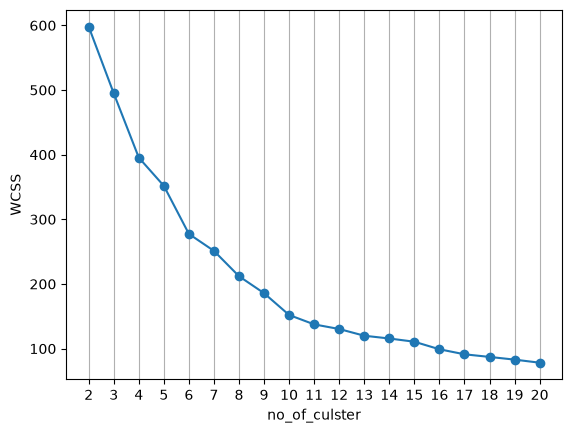

In [20]:
plt.plot([i for i in range(2,21)], wcss, marker="o")
plt.xlabel("no_of_culster")
plt.xticks([i for i in range(2,21)])
plt.ylabel("WCSS")
plt.grid(axis="x")
plt.show()

In [21]:
kn = KMeans(n_clusters=5, init="k-means++", random_state=42)
dataset["predict"] = kn.fit_predict(dataset)

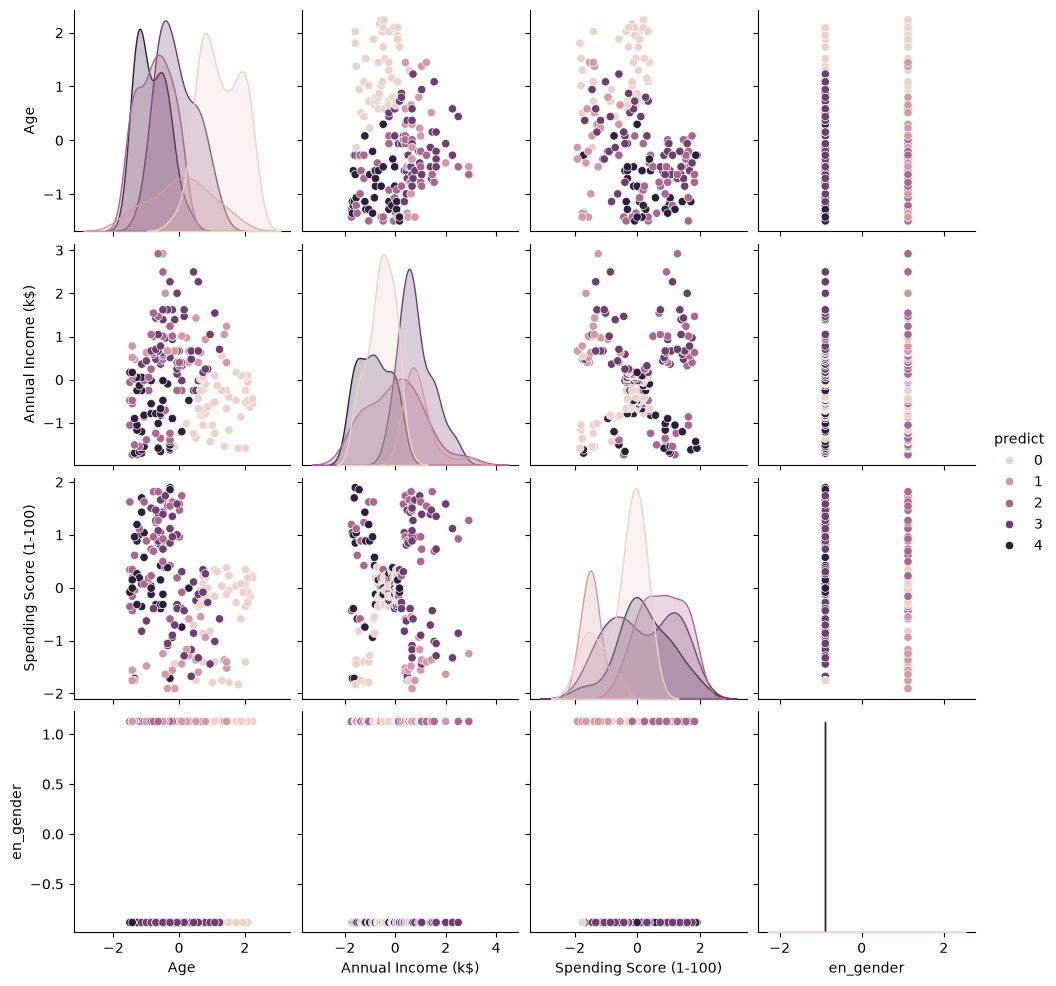

In [22]:
sns.pairplot(data=dataset, hue="predict")
plt.show()

In [23]:
dataset = dataset.drop(columns="predict", errors="ignore")

# Silhouettte Score

In [24]:
from sklearn.metrics import silhouette_score

In [25]:
silhouette_score(dataset, labels=kn.labels_)*100

27.19102346618833

In [26]:
ss1 = []

for i in range(2,21):
    km1 = KMeans(n_clusters=i, init="k-means++", random_state=42)
    km1.fit(dataset)
    ss1.append(silhouette_score(dataset, km1.labels_))

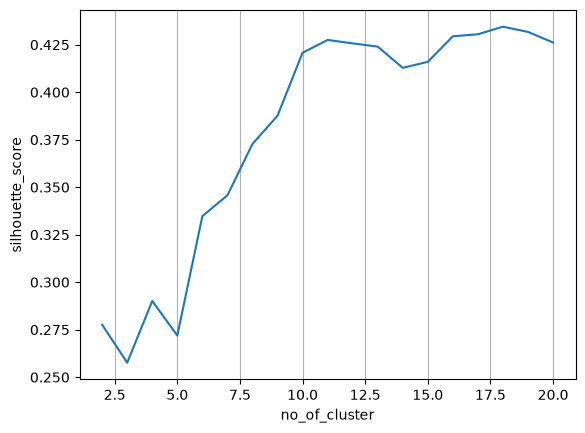

In [27]:
plt.plot([i for i in range(2,21)], ss1)
plt.xlabel("no_of_cluster")
plt.ylabel("silhouette_score")
plt.grid(axis="x")
plt.show()

# Hierarchical Clustering

In [28]:
import scipy.cluster.hierarchy as sc

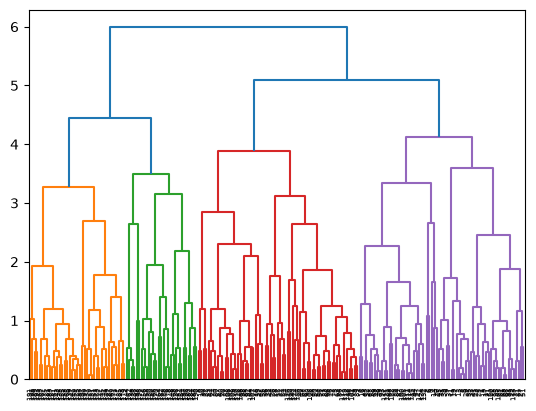

In [29]:
sc.dendrogram(sc.linkage(dataset, method="complete", metric="euclidean"))
plt.show()

In [30]:
from sklearn.cluster import AgglomerativeClustering

In [31]:
a = AgglomerativeClustering(n_clusters=5, linkage="complete")
dataset["predict"] = a.fit_predict(dataset)

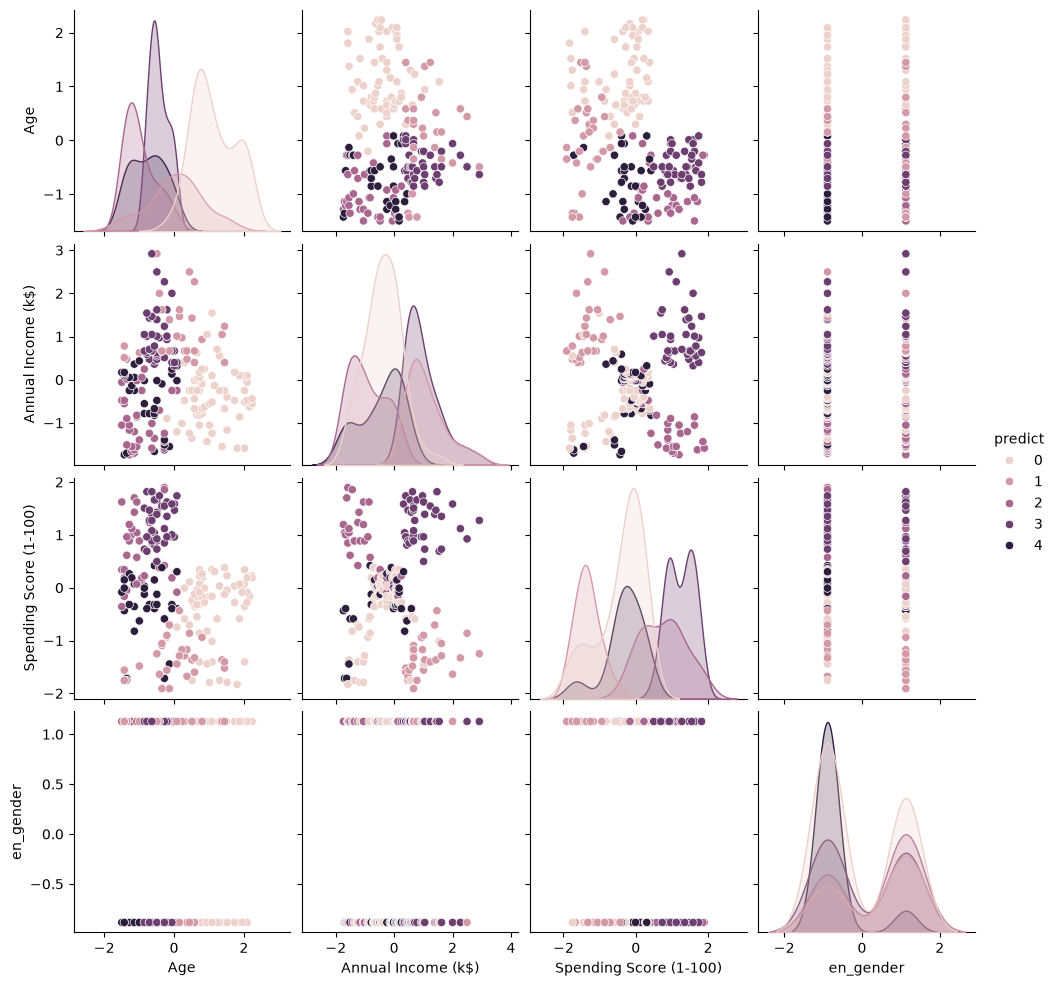

In [32]:
sns.pairplot(data=dataset, hue="predict")
plt.show()

In [33]:
dataset = dataset.drop(columns="predict", errors="ignore")

# sihouette Score

In [34]:
from sklearn.metrics import silhouette_score

In [35]:
silhouette_score(dataset, a.labels_)*100

24.330923091806703

In [36]:
ss2 = []

for i in range(2,21):
    a = AgglomerativeClustering(n_clusters=i, linkage="complete")
    a.fit(dataset)
    ss2.append(silhouette_score(dataset, labels=a.labels_))

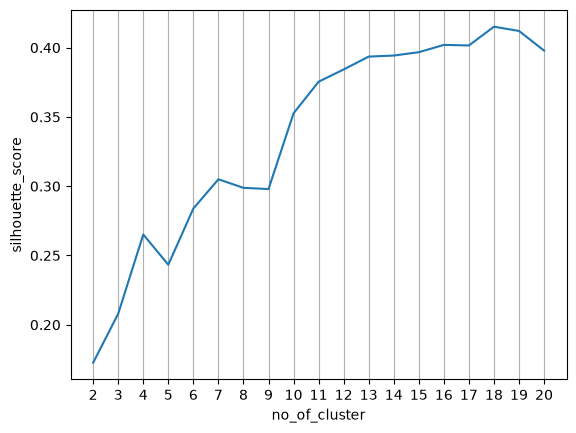

In [37]:
plt.plot([i for i in range(2,21)], ss2)
plt.xlabel("no_of_cluster")
plt.xticks([i for i in range(2,21)])
plt.ylabel("silhouette_score")
plt.grid(axis="x")
plt.show()

# DBSCAN CLUSTERING 

In [38]:
from sklearn.cluster import DBSCAN

In [39]:
db = DBSCAN(eps=0.8, min_samples=5)
dataset["predict"] = db.fit_predict(dataset)

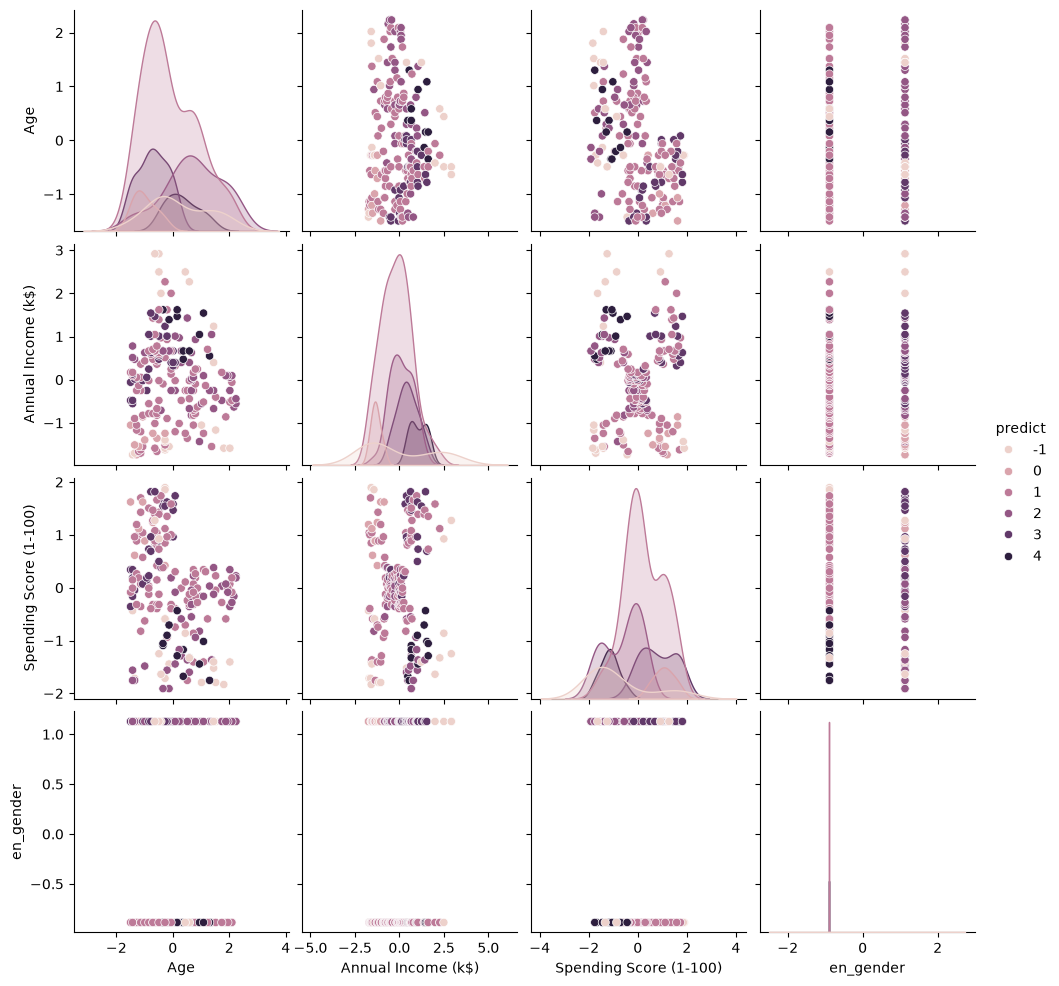

In [40]:
sns.pairplot(data=dataset, hue="predict")
plt.show()

In [41]:
dataset = dataset.drop(columns="predict", errors="ignore")

# sihouette score

In [42]:
from sklearn.metrics import silhouette_score

In [43]:
labels = db.labels_
mask = labels != -1
score = silhouette_score(dataset[mask], labels[mask])*100
score

22.72598949349188

# KMeans with two Features

In [44]:
feat2 = dataset[["Annual Income (k$)", "Spending Score (1-100)"]]
km2 = KMeans(n_clusters=5, init="k-means++", random_state=42, n_init=10).fit(feat2)
print("silhouette:", silhouette_score(feat2, km2.labels_) * 100)

silhouette: 55.46571631111091


In [45]:
dataset["kmeans2"] = km2.labels_
orig = pd.read_csv(r"customer_segmentation data.csv")
orig["Cluster"] = dataset["kmeans2"]
orig.groupby("Cluster")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1)

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,42.7,55.3,49.5
1,32.7,86.5,82.1
2,25.3,25.7,79.4
3,41.1,88.2,17.1
4,45.2,26.3,20.9


In [46]:
print(orig["Cluster"].value_counts().sort_index())
pd.crosstab(orig["Cluster"], orig["Gender"], normalize="index").round(2)

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


Gender,Female,Male
Cluster,,
0,0.59,0.41
1,0.54,0.46
2,0.59,0.41
3,0.46,0.54
4,0.61,0.39


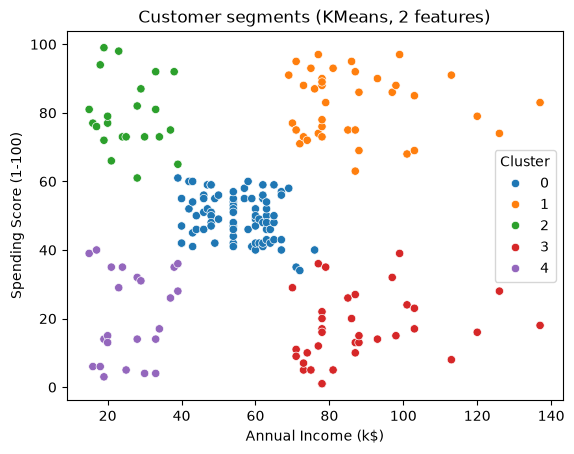

In [47]:
sns.scatterplot(data=orig, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", palette="tab10")
plt.title("Customer segments (KMeans, 2 features)")
plt.show()

# KMeans with four features

In [48]:
dataset["kmeans"] = kn.labels_
dataset.head()

,Age,Annual Income (k$),Spending Score (1-100),en_gender,kmeans2,kmeans
0,-1.424569,-1.738999,-0.434801,1.128152,4,2
1,-1.281035,-1.738999,1.195704,1.128152,2,2
2,-1.352802,-1.700830,-1.715913,-0.886405,4,4
3,-1.137502,-1.700830,1.040418,-0.886405,2,4
4,-0.563369,-1.662660,-0.395980,-0.886405,4,4


In [49]:
dataset.groupby("kmeans")[cols].mean().round(2)

,Age,Annual Income (k$),Spending Score (1-100),en_gender
kmeans,,,,
0,1.26,-0.55,-0.42,0.14
1,0.05,0.94,-1.40,1.13
2,-0.73,0.01,0.78,1.13
3,-0.07,0.82,0.16,-0.89
4,-0.83,-0.83,0.23,-0.89


In [50]:
dataset["kmeans"].value_counts().sort_index()

kmeans
0    51
1    20
2    42
3    49
4    38
Name: count, dtype: int64

In [51]:
dataset.groupby("kmeans")[cols].mean().round(2).T

kmeans,0,1,2,3,4
Age,1.26,0.05,-0.73,-0.07,-0.83
Annual Income (k$),-0.55,0.94,0.01,0.82,-0.83
Spending Score (1-100),-0.42,-1.40,0.78,0.16,0.23
en_gender,0.14,1.13,1.13,-0.89,-0.89


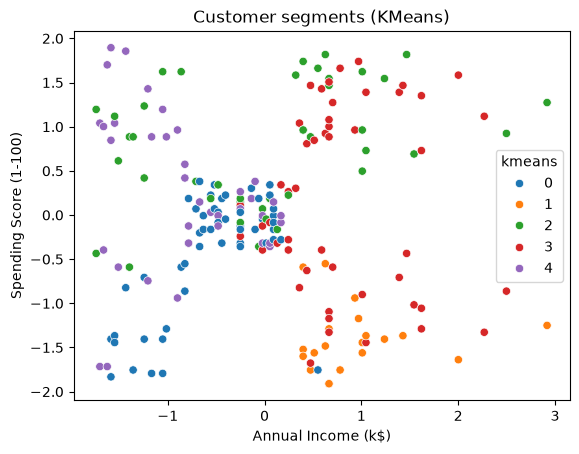

In [52]:
sns.scatterplot(data=dataset, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="kmeans", palette="tab10")
plt.title("Customer segments (KMeans)")
plt.show()

# Hierarchical & DBSCAN with two features 

In [53]:
h2 = AgglomerativeClustering(n_clusters=5, linkage="ward").fit(feat2)
h2_score = silhouette_score(feat2, h2.labels_) * 100

d2 = DBSCAN(eps=0.40, min_samples=8).fit(feat2)
m = d2.labels_ != -1
d2_score = silhouette_score(feat2[m], d2.labels_[m]) * 100
noise2 = (~m).sum()
print(h2_score, d2_score, noise2)

55.38089226688662 54.89916076416773 25


# Silhouette Score Comparison 

In [54]:
comparison2 = pd.DataFrame({
    "Model": ["KMeans (4 features)", "Hierarchical (4 features)", "DBSCAN (4 features)",
              "KMeans (2 features)", "Hierarchical (2 features)", "DBSCAN (2 features)"],
    "Silhouette": [27.19, 24.33, 22.73, 55.47, h2_score, d2_score],
    "Noise points": [0, 0, 19, 0, 0, noise2],
}).round(2)
comparison2

,Model,Silhouette,Noise points
0,KMeans (4 features),27.19,0
1,Hierarchical (4 features),24.33,0
2,DBSCAN (4 features),22.73,19
3,KMeans (2 features),55.47,0
4,Hierarchical (2 features),55.38,0
5,DBSCAN (2 features),54.90,25


# The final model

KMeans on income and spending (5 clusters, silhouette 55.47). On these two features KMeans, 
hierarchical clustering and DBSCAN score almost the same (55.47, 55.38, 54.90), but 
KMeans assigns every customer to a segment and is the easiest to explain. 
With all four features the score was lower (27.19) and the clusters were mostly split by gender,
a binary variable, so they were less useful as segments. Age and gender are therefore used only to describe the segments.

# Segments

| Cluster | Customers | Age | Income (k$) | Spending | Segment | Suggested action |
|---|---|---|---|---|---|---|
| 0 | 81 | 42.7 | 55.3 | 49.5 | Standard customers | Regular promotions |
| 1 | 39 | 32.7 | 86.5 | 82.1 | High income, high spending | Premium offers, loyalty programme |
| 2 | 22 | 25.3 | 25.7 | 79.4 | Young, low income, high spending | Affordable trendy products, bundles |
| 3 | 35 | 41.1 | 88.2 | 17.1 | High income, low spending | Personalised premium offers to raise spending |
| 4 | 23 | 45.2 | 26.3 | 20.9 | Low income, low spending | Low-cost value deals |

In [55]:
import joblib
from sklearn.preprocessing import StandardScaler

# scaler for the two original columns (same scaling that km2 was trained on)
scaler2 = StandardScaler().fit(orig[["Annual Income (k$)", "Spending Score (1-100)"]])

segment_names = {
    0: "Standard customers",
    1: "High income, high spending",
    2: "Young, low income, high spending",
    3: "High income, low spending",
    4: "Low income, low spending",
}

joblib.dump(scaler2, "scaler.joblib")
joblib.dump(km2, "kmeans_model.joblib")
joblib.dump(segment_names, "segment_names.joblib")

['segment_names.joblib']